# Assignment 2 — Question 2: Sampling and bootstrap

**Population:** all 768 records in `data_raw/diabetes.csv`, as explicitly directed in the assignment.  
**Reproducible seed:** 42.  
**Sample:** 25 records without replacement for parts (a)–(b).  
**Bootstrap:** 500 independent resamples of 150 rows **with replacement** from the full population for part (c).  
**Percentile choice in (c):** the 98th percentile, to match part (b), because the question does not specify which percentile.

Population summaries treat the dataset as the entire population, and therefore population standard deviation uses `ddof=0`. Each resample's standard deviation uses `ddof=1`, the usual sample statistic. Zeros in `Glucose`, `BloodPressure`, and `BMI` are kept **exactly as supplied**; some may represent unavailable clinical measures, but replacing them would change the defined assignment population and was not requested.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd()/'data_raw'/'diabetes.csv').exists() else Path.cwd().parent
population = pd.read_csv(ROOT/'data_raw'/'diabetes.csv')
expected=['Pregnancies','Glucose','BloodPressure','SkinThickness','Insulin','BMI','DiabetesPedigreeFunction','Age','Outcome']
assert set(expected).issubset(population), 'Unexpected diabetes.csv columns'
assert len(population)==768, 'Assignment expects 768 rows'
SEED=42
rng = np.random.default_rng(SEED)
print('Population shape:',population.shape)
print('Missing values:',population.isna().sum().to_dict())
display(population.head())

Population shape: (768, 9)
Missing values: {'Pregnancies': 0, 'Glucose': 0, 'BloodPressure': 0, 'SkinThickness': 0, 'Insulin': 0, 'BMI': 0, 'DiabetesPedigreeFunction': 0, 'Age': 0, 'Outcome': 0}


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## (a) Random sample of 25: mean and highest Glucose

Sample without replacement using a seeded random generator. Compare the sample's mean and maximum to corresponding full-population values. The maximum is strongly sample-size dependent, so a lower sample maximum is not evidence of a different underlying population.

,Statistic,Sample (n=25),Population (N=768)
0,Mean Glucose,113.44,120.895
1,Maximum Glucose,179.00,199.000


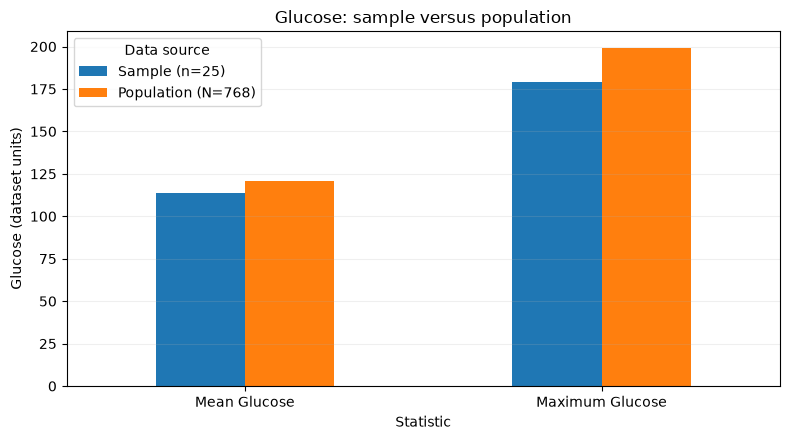

Sample mean differs by -7.45; sample maximum differs by -20.


In [2]:
sample_idx = rng.choice(len(population),size=25,replace=False)
sample = population.iloc[sample_idx].copy()
glucose_metrics = pd.DataFrame({'Statistic':['Mean Glucose','Maximum Glucose'],
                                 'Sample (n=25)':[sample.Glucose.mean(),sample.Glucose.max()],
                                 'Population (N=768)':[population.Glucose.mean(),population.Glucose.max()]})
display(glucose_metrics.round(3))
ax=glucose_metrics.set_index('Statistic')[['Sample (n=25)','Population (N=768)']].plot.bar(figsize=(8,4.5),rot=0)
ax.set(title='Glucose: sample versus population',ylabel='Glucose (dataset units)')
ax.legend(title='Data source');ax.grid(axis='y',alpha=.2)
plt.tight_layout();plt.show()
print(f"Sample mean differs by {sample.Glucose.mean()-population.Glucose.mean():+.2f}; sample maximum differs by {sample.Glucose.max()-population.Glucose.max():+.0f}.")

## (b) 98th percentile of BMI

`numpy.percentile` uses linear interpolation by default. The same calculation is applied to sample and population.

,Group,BMI_98th_percentile
0,Sample (n=25),42.516
1,Population (N=768),47.526


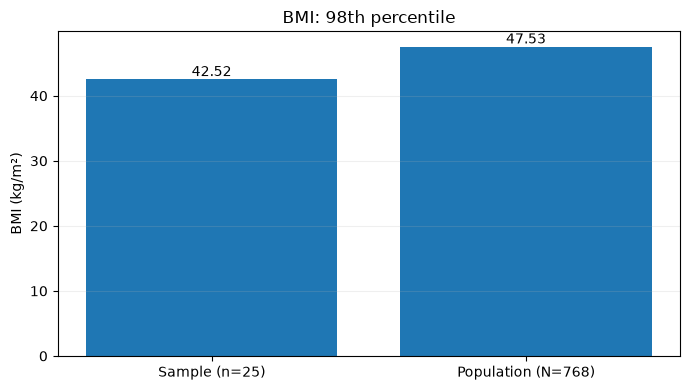

Difference (sample minus population): -5.01 BMI units


In [3]:
percentile_level=98
bmi_sample=np.percentile(sample.BMI,percentile_level)
bmi_population=np.percentile(population.BMI,percentile_level)
bmi_comparison=pd.DataFrame({'Group':['Sample (n=25)','Population (N=768)'],'BMI_98th_percentile':[bmi_sample,bmi_population]})
display(bmi_comparison.round(3))
fig,ax=plt.subplots(figsize=(7,4))
ax.bar(bmi_comparison.Group,bmi_comparison.BMI_98th_percentile)
ax.set(title='BMI: 98th percentile',ylabel='BMI (kg/m²)');ax.grid(axis='y',alpha=.2)
for i,v in enumerate(bmi_comparison.BMI_98th_percentile):ax.text(i,v,f'{v:.2f}',ha='center',va='bottom')
plt.tight_layout();plt.show()
print(f'Difference (sample minus population): {bmi_sample-bmi_population:+.2f} BMI units')

## (c) Bootstrap: 500 samples × 150 observations

Draw 500 samples of size 150 **with replacement from the full 768-record population**, compute for each sample (i) mean, (ii) sample standard deviation, and (iii) 98th percentile of BloodPressure, and then average each statistic across the 500 resamples. Compare these average bootstrap statistics to population statistics. A bootstrap *distribution* is also plotted for each metric, with the population statistic overlaid as a reference line. Since the resampling pool is the full specified population rather than the 25-observation sample, this is more precisely repeated resampling from a known empirical population.

,Population statistic,Mean across 500 resamples,Bootstrap minus population
Mean,69.105,69.136,0.031
Standard deviation,19.343,19.059,-0.284
98th percentile,99.320,97.656,-1.664


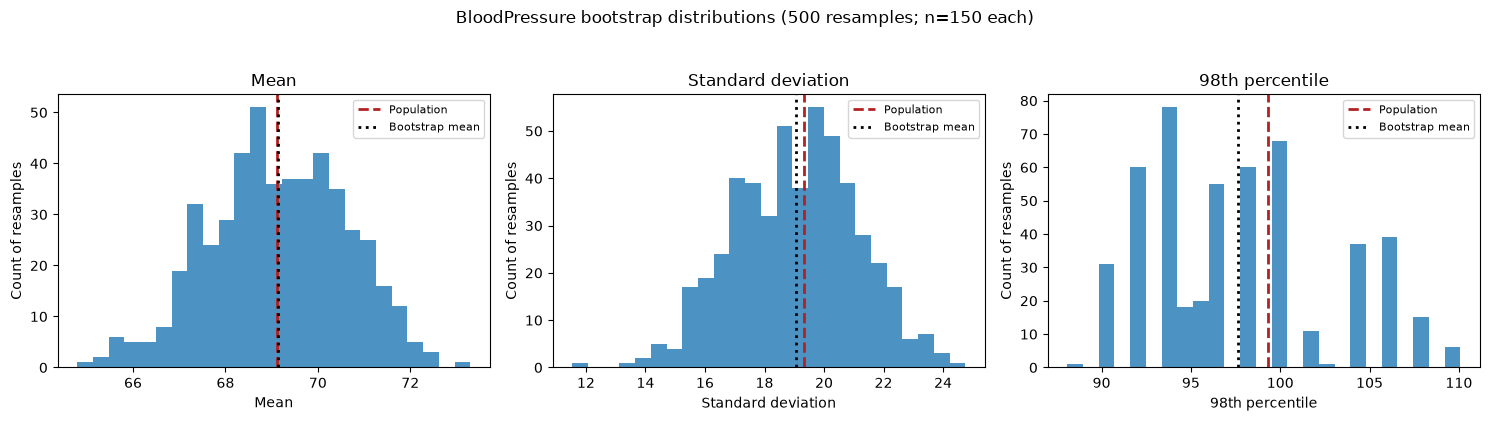

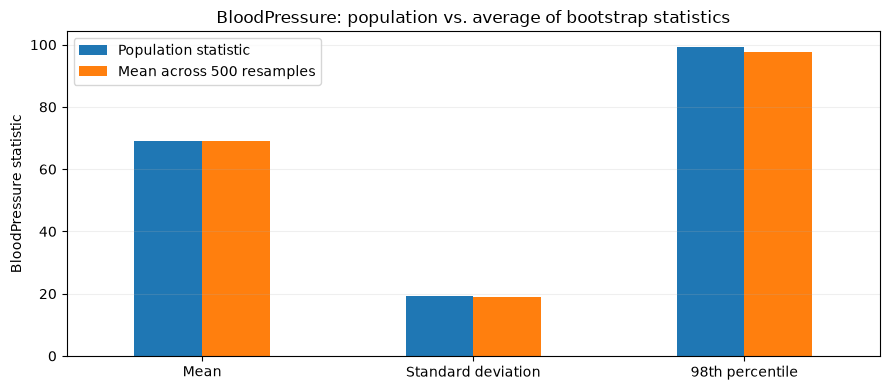

In [4]:
B=500
n_boot=150
bp=population.BloodPressure.to_numpy()
bootstrap_indices=rng.integers(0,len(bp),size=(B,n_boot))
bootstrap_bp=bp[bootstrap_indices]
bootstrap_stats=pd.DataFrame({
    'Mean':bootstrap_bp.mean(axis=1),
    'Standard deviation':bootstrap_bp.std(axis=1,ddof=1),
    '98th percentile':np.percentile(bootstrap_bp,98,axis=1)
})
pop_stats=pd.Series({'Mean':bp.mean(),'Standard deviation':bp.std(ddof=0),'98th percentile':np.percentile(bp,98)})
comparison=pd.DataFrame({'Population statistic':pop_stats,'Mean across 500 resamples':bootstrap_stats.mean()})
comparison['Bootstrap minus population']=comparison['Mean across 500 resamples']-comparison['Population statistic']
display(comparison.round(3))
fig,axs=plt.subplots(1,3,figsize=(15,4))
for ax,metric in zip(axs,bootstrap_stats.columns):
    ax.hist(bootstrap_stats[metric],bins=25,alpha=.8)
    ax.axvline(pop_stats[metric],color='firebrick',linestyle='--',linewidth=2,label='Population')
    ax.axvline(bootstrap_stats[metric].mean(),color='black',linestyle=':',linewidth=2,label='Bootstrap mean')
    ax.set(title=metric,xlabel=metric,ylabel='Count of resamples')
    ax.legend(fontsize=8)
plt.suptitle('BloodPressure bootstrap distributions (500 resamples; n=150 each)',y=1.04)
plt.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(9,4))
comparison[['Population statistic','Mean across 500 resamples']].plot.bar(ax=ax,rot=0)
ax.set(title='BloodPressure: population vs. average of bootstrap statistics',ylabel='BloodPressure statistic')
ax.grid(axis='y',alpha=.2);plt.tight_layout();plt.show()
assert bootstrap_bp.shape==(500,150)
assert bootstrap_indices.max()<len(bp) and bootstrap_indices.min()>=0

## Findings and interpretation

The printed values below summarize the **actual executed** calculations rather than supplying expected or invented results. In 500 resamples, the bootstrap average of the mean should generally be near the population mean, but each finite simulation varies. The standard deviation may differ slightly because it averages sample standard deviations (`ddof=1`) while the reference is the defined population standard deviation (`ddof=0`). An extreme 98th percentile may be noticeably less stable than the mean, especially with only 150 observations per resample. The supplied dataset contains zero BloodPressure records; zeros are not silently removed or replaced. No causal or clinical conclusions follow from these comparisons.

In [5]:
print('OBSERVED FINDINGS')
for metric in comparison.index:
    r=comparison.loc[metric]
    print(f"{metric}: population {r['Population statistic']:.3f}; mean bootstrap {r['Mean across 500 resamples']:.3f}; difference {r['Bootstrap minus population']:+.3f}.")
print('Zero BloodPressure entries included:',int((population.BloodPressure==0).sum()))
print('All resamples drawn with replacement; same population used as defined in assignment.')
# Save small, reproducible analysis tables to results/.
comparison.round(6).to_csv(ROOT/'results'/'blood_pressure_bootstrap_comparison.csv')
bootstrap_stats.to_csv(ROOT/'results'/'blood_pressure_bootstrap_statistics.csv',index=False)
glucose_metrics.to_csv(ROOT/'results'/'glucose_comparison.csv',index=False)
bmi_comparison.to_csv(ROOT/'results'/'bmi_comparison.csv',index=False)
print('Exported comparison tables to results/.')

OBSERVED FINDINGS
Mean: population 69.105; mean bootstrap 69.136; difference +0.031.
Standard deviation: population 19.343; mean bootstrap 19.059; difference -0.284.
98th percentile: population 99.320; mean bootstrap 97.656; difference -1.664.
Zero BloodPressure entries included: 35
All resamples drawn with replacement; same population used as defined in assignment.
Exported comparison tables to results/.
